# LightGBM mixto y CRNN pequeña

**Elegiría DART + CRNN pequeña.** En 56 noches de 34 personas, la combinación elevó el F1 macro de **80,10 % a 80,86 %**. Mejoró en las cinco rondas. El intervalo orientativo del 95 % para la ganancia, remuestreando personas por cohorte, fue **+0,37 a +1,21 puntos porcentuales**.

**Qué mide el resultado global.** Son 75.612 segmentos etiquetados de 30 segundos, de 44 noches de Telemetry y 12 de Cassette. Se agrupan las predicciones de prueba de las cinco rondas y se promedian los F1 de W, N1, N2, N3 y REM. Cada persona se evalúa una vez, con todas sus noches excluidas del entrenamiento de esa ronda.

**Cómo se combinan.** DART usa características tabulares. La CRNN pequeña lee secuencias de esas características. Para cada segmento y etapa se calcula `0,75 × P(DART) + 0,25 × P(CRNN)` y se elige la etapa con la suma más alta.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# El propio notebook incluye los conteos por ronda y cohorte en sus metadatos.
p = next(p for d in (Path.cwd(), *Path.cwd().parents)
         for p in (d/'resumen_lightgbm_crnn.ipynb', d/'Notebooks/experiments/resumen_lightgbm_crnn.ipynb') if p.is_file())
datos = json.loads(p.read_text('utf-8'))['metadata']['evidencia']
etapas = datos['orden']
principales = ['DART', 'CRNN pequeña', 'DART + CRNN']
def matriz(modelo, ronda=None, cohorte=None):
    piezas = []
    for clave, valores in datos['cuentas'][modelo].items():
        num, grupo = clave.split('-')
        if (ronda is None or int(num)==ronda) and (cohorte is None or grupo==cohorte):
            cm = np.asarray(valores)
            assert cm.sum()==datos['poblacion'][clave][2]
            piezas.append(cm)
    return np.stack(piezas).sum(axis=0)

def estadisticas(cm):
    filas, cols = cm.sum(1), cm.sum(0)
    f1 = np.divide(2*np.diag(cm),filas+cols,out=np.zeros(len(cm)),where=(filas+cols)!=0)
    accuracy = cm.trace()/cm.sum()
    esperado = np.dot(filas/cm.sum(),cols/cm.sum())
    return [f1.mean(), accuracy, (accuracy-esperado)/(1-esperado)]

def resumen(modelos, ronda=None, cohorte=None):
    return pd.DataFrame([estadisticas(matriz(m,ronda,cohorte)) for m in modelos],
                        index=modelos,columns=['F1 macro','Exactitud','Kappa'])
def tabla(frame):
    return frame.style.format({'F1 macro':'{:.2%}','Exactitud':'{:.2%}','Kappa':'{:.4f}'})

display(tabla(resumen(principales)))

,F1 macro,Exactitud,Kappa
DART,80.10%,85.96%,0.8074
CRNN pequeña,79.56%,85.90%,0.8054
DART + CRNN,80.86%,86.69%,0.8171


## Matrices de confusión globales

Las filas indican la etapa real y las columnas la etapa predicha. Los números cuentan segmentos; el color indica el porcentaje de cada fila. En N1 se ve con qué etapas se confunde el sueño ligero.

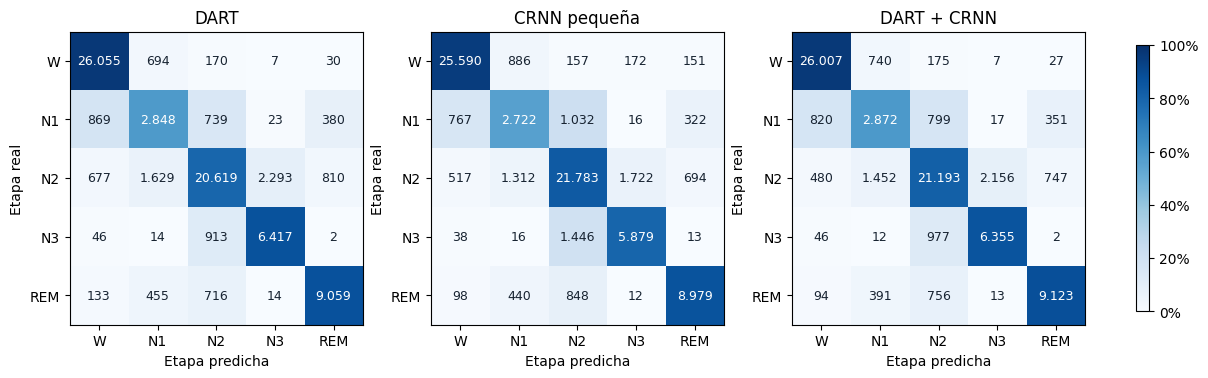

In [2]:
from matplotlib.ticker import PercentFormatter
fig, ejes = plt.subplots(1,3,figsize=(12,3.8),layout='constrained')
for ax, modelo in zip(ejes,principales):
    cm = matriz(modelo)
    frac = cm/cm.sum(1,keepdims=True)
    im=ax.imshow(frac,vmin=0,vmax=1,cmap='Blues')
    ax.set(xticks=range(5),xticklabels=etapas,yticks=range(5),yticklabels=etapas,
           xlabel='Etapa predicha',ylabel='Etapa real',title=modelo)
    for (i,j),valor in np.ndenumerate(cm):
        ax.text(j,i,f'{valor:,}'.replace(',','.'),ha='center',va='center',fontsize=9,
                color='white' if frac[i,j]>.55 else '#172331')
fig.colorbar(im,ax=ejes,shrink=.75,format=PercentFormatter(1))
plt.show()

## Tiempo de entrenamiento

Referencia de la primera ronda: 27 personas, 45 noches y 59.719 segmentos de entrenamiento. Los tiempos comienzan con las entradas preparadas. Para las combinaciones se suman los componentes ajustados en serie; la mezcla de probabilidades usa pesos fijos.

In [3]:
t=datos['tiempos']
v6=t['encoder_v6']+t['vectores_v6']+t['cabezal_hmm']
def duracion(s):
    horas, resto=divmod(round(s),3600)
    minutos, segundos=divmod(resto,60)
    return (f'{horas} h ' if horas else '') + (f'{minutos} min ' if minutos or horas else '') + f'{segundos} s'
display(pd.DataFrame([
    ['DART',duracion(t['DART']),'Ajuste medido en CPU'],
    ['CRNN pequeña',duracion(t['Original']),'Ajuste medido en CPU'],
    ['DART + CRNN',duracion(t['DART']+t['Original']),'Suma de ambos ajustes'],
    ['V6',duracion(v6),'Estimación con CRNN en GPU, extracción de vectores y LightGBM + HMM'],
    ['DART + V6',duracion(t['DART']+v6),'Estimación de ambos ajustes en serie']
],columns=['Modelo','Una ronda','Alcance']).set_index('Modelo'))

,Una ronda,Alcance
Modelo,,
DART,7 min 1 s,Ajuste medido en CPU
CRNN pequeña,14 s,Ajuste medido en CPU
DART + CRNN,7 min 15 s,Suma de ambos ajustes
V6,5 h 17 min 14 s,"Estimación con CRNN en GPU, extracción de vect..."
DART + V6,5 h 24 min 15 s,Estimación de ambos ajustes en serie


## Otros hallazgos

La **CRNN residual** dio el F1 global numéricamente más alto, **80,87 %**, frente a **80,86 %** de la pequeña original. La diferencia observada fue inferior a 0,01 puntos porcentuales y el ajuste de la residual tomó unos 26 s frente a 14 s en la primera ronda.

El **V6 del compañero** sigue otra arquitectura: CRNN → LightGBM → HMM. Solo completó la primera ronda. La siguiente comparación usa exactamente las mismas 11 noches, 7 personas y 15.893 segmentos para todos sus modelos.

In [4]:
alternativas=['DART','DART + CRNN','V6','DART + V6']
display(tabla(resumen(alternativas,ronda=1)))
def detalle(titulo,contenido):
    return f'<details><summary>{titulo}</summary>{contenido}</details>'
def matrices_html(modelos,ronda=None):
    piezas=[]
    for m in modelos:
        frame=pd.DataFrame(matriz(m,ronda),index=pd.Index(etapas,name='Real / predicha'),columns=etapas)
        piezas.append(f'<div><strong>{m}</strong>{frame.to_html()}</div>')
    return '<div style="display:flex;gap:1.5em;flex-wrap:wrap">'+''.join(piezas)+'</div>'
display(HTML(detalle('Matrices de confusión de la primera ronda', matrices_html(alternativas,1))))
display(HTML(detalle('Variante residual · estadísticas y matriz globales',
                     tabla(resumen(['DART + Residual'])).to_html()+matrices_html(['DART + Residual']))))
cohortes=pd.concat({c:resumen(principales,cohorte=c) for c in ['Telemetry','Cassette']},names=['Cohorte','Modelo'])
display(HTML(detalle('Resultados de las cinco rondas por cohorte', tabla(cohortes).to_html())))

,F1 macro,Exactitud,Kappa
DART,81.94%,87.45%,0.8262
DART + CRNN,82.74%,88.05%,0.8343
V6,77.49%,82.32%,0.7536
DART + V6,83.64%,88.93%,0.8461


,W,N1,N2,N3,REM
Real / predicha,,,,,
W,6147,102,13,4,11
N1,102,768,183,4,140
N2,68,306,3926,570,253
N3,2,0,42,1168,0
REM,4,37,150,4,1889
,W,N1,N2,N3,REM
Real / predicha,,,,,
W,6128,129,10,4,6
N1,99,786,182,1,129


Los conteos de confusión están guardados en este archivo. Los cálculos y las figuras se pueden repetir sin cargar los EDF ni reentrenar modelos. La evaluación es de desarrollo y aún falta una cohorte externa para comprobar la generalización. Fuentes del proyecto: [validación global](lightgbm_transiciones_sueno.ipynb), [variantes de CRNN](refinamiento_crnn_pequena.ipynb), [V6 de la primera ronda](fusion_dart_v6_companero.ipynb) y [tiempos](comparacion_justa_lightgbm_v6.ipynb).